# Задача 8. Большой детектор и быстрый поиск ФЭУ

$R = 15$ м, $N = 2000$, $r = 10$ см, $a = 0.5$. ФЭУ расставлены, как в задаче 1, по спирали Фибоначчи.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from detector import Detector, fibonacci_sphere
from source import Source

det = Detector(R=15.0, N=2000, r=0.10, a=0.5, rng=8)
print(det.pmt_positions.shape)
print(f"мин. расстояние между ФЭУ: {det.min_pmt_distance():.3f} м")
print(f"покрытие: {det.coverage():.4%}")

(2000, 3)
мин. расстояние между ФЭУ: 1.037 м
покрытие: 2.2222%


расстояние до ближайшего соседа: 1.137 ± 0.015 м (идеальная гексагональная решётка: 1.278 м)


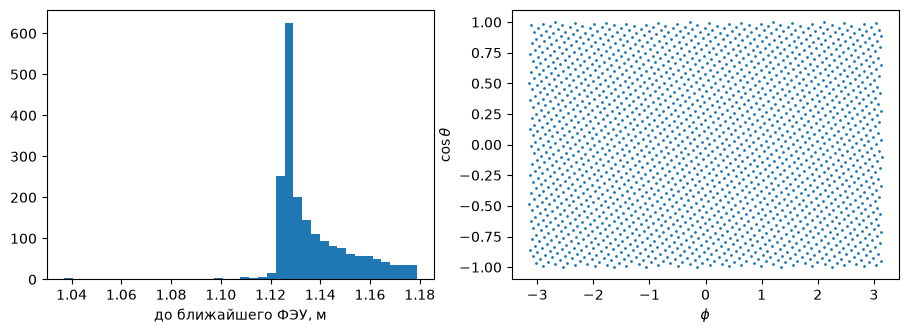

In [2]:
d = np.linalg.norm(det.pmt_positions[:, None] - det.pmt_positions[None], axis=2)
np.fill_diagonal(d, np.inf)
nearest = d.min(axis=1)
print(f"расстояние до ближайшего соседа: {nearest.mean():.3f} ± {nearest.std():.3f} м "
      f"(идеальная гексагональная решётка: {np.sqrt(8*np.pi/np.sqrt(3)/det.N)*det.R:.3f} м)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(nearest, bins=40); ax[0].set_xlabel('до ближайшего ФЭУ, м')
th = np.arccos(det.pmt_directions[:, 2]); ph = np.arctan2(det.pmt_directions[:, 1], det.pmt_directions[:, 0])
ax[1].scatter(ph, np.cos(th), s=1); ax[1].set_xlabel(r'$\phi$'); ax[1].set_ylabel(r'$\cos\theta$')
plt.show()

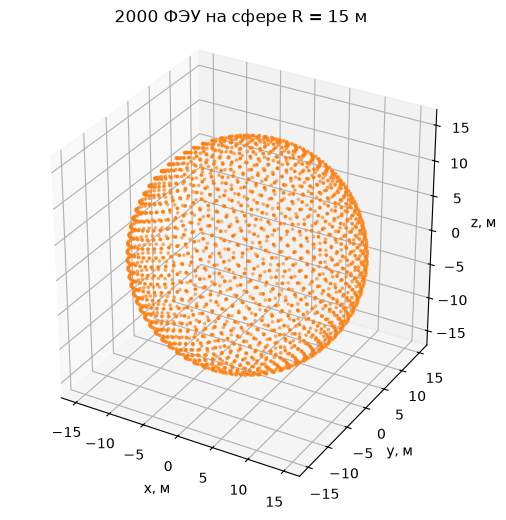

In [3]:
fig = plt.figure(figsize=(6, 6))
ax3 = fig.add_subplot(projection='3d')
ax3.scatter(*det.pmt_positions.T, s=3, color='C1')
ax3.set_box_aspect((1, 1, 1))
ax3.set_xlabel('x, м'); ax3.set_ylabel('y, м'); ax3.set_zlabel('z, м')
ax3.set_title(f'{det.N} ФЭУ на сфере R = {det.R:g} м')
plt.show()

Интерактивный виджет k3d виден только при запуске ноутбука: GitHub и другие просмотрщики его не показывают. Статичный рисунок выше показывает ту же геометрию; точки увеличены, катоды в масштабе были бы почти не видны.

In [4]:
import k3d
plot = k3d.plot()
plot += k3d.points(det.pmt_positions.astype(np.float32), point_size=0.5, color=0xff8800)
plot.display()

## Оптимизация поиска ФЭУ

**Перебор (`brute`)**, как в задаче 1: для каждой точки проверяются все $N$ катодов — матрица $(M, N)$, сложность $O(MN)$. При $N = 2000$ и $10^5$ фотонов это $2\cdot10^8$ проверок и ~3 ГБ промежуточных массивов.

**Сетка (`grid`)** — собственный алгоритм. Поверхность делится на пояса одинаковой угловой ширины $\Delta\theta$, а число ячеек по $\phi$ в поясе пропорционально $\sin\theta$. Так все ячейки почти квадратные, $\sim\Delta\theta\times\Delta\theta$, в том числе у полюсов: там пояс состоит из нескольких ячеек (6 вокруг самого полюса), а не из 160 узких клиньев. Ячейки нумеруются подряд: ячейка $(i, j)$ имеет номер `offset[i] + j`. Один раз при построении для каждой ячейки запоминается короткий список ФЭУ-кандидатов — тех, чей катод может задевать ячейку: угловое расстояние от центра ячейки до оси ФЭУ не больше $\alpha$ + полуразмер ячейки ($\sin\alpha = r/R$). Списки дополняются $-1$ до общей длины $K$ и хранятся в массиве `(n_cells, K)`. Для точки номер ячейки вычисляется за $O(1)$ арифметикой, а проверяются только её $K \ll N$ кандидатов: сложность $O(MK)$. По умолчанию $\Delta\theta$ вдвое меньше расстояния между соседними ФЭУ, и $K = 1$–$2$.

*Первая версия* сетки делила поверхность с равным шагом по $\cos\theta$ и по $\phi$. У полюсов такие ячейки — длинные узкие клинья (самый полярный пояс простирается на ~20° от полюса), в них попадало до $K = 37$ кандидатов при среднем 4.5, и поскольку проверяются все $K$ позиций таблицы, сетка была лишь в 7 раз быстрее перебора и в 3 раза медленнее k-d дерева.

**k-d дерево (`kdtree`, scipy)**: ближайший к точке центр ФЭУ за $O(\log N)$, затем одна проверка катода. Это корректно, потому что катоды не перекрываются: если точка на катоде $k$, угловое расстояние до его оси $<\alpha$, а до любой другой оси $> \alpha$, т.е. $k$ — ближайший.

Все три метода дают одинаковый результат — проверено тестом `test_fast_search_matches_brute`, в том числе на точках в пределах ±2% от края катода.

сетка: 80 поясов, 8308 ячеек, K = 1, кандидатов в ячейке в среднем 0.60
ячеек с 0 / 1 / ... кандидатами: [3307 5001]
ячеек в поясах у полюса: [ 6 13 19 25]  на экваторе: 160

 n_theta  ячеек   K  среднее   мс/20000 точек
     20    548   9     6.83       9.73
     40   2120   4     1.93       5.76


     80   8308   1     0.60       2.37


    120  18576   1     0.32       2.18


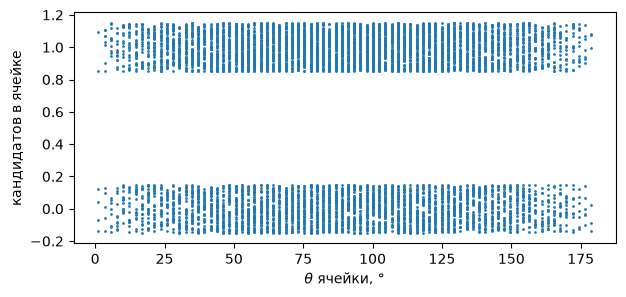

In [5]:
g = det.build_grid()
n_cand = (g['table'] >= 0).sum(axis=1)
print(f"сетка: {g['n_theta']} поясов, {g['table'].shape[0]} ячеек, K = {g['table'].shape[1]}, "
      f"кандидатов в ячейке в среднем {n_cand.mean():.2f}")
print("ячеек с 0 / 1 / ... кандидатами:", np.bincount(n_cand))
print("ячеек в поясах у полюса:", g['n_phi'][:4], " на экваторе:", g['n_phi'][g['n_theta'] // 2])

pts_t = det.R * fibonacci_sphere(20_000)
print("\n n_theta  ячеек   K  среднее   мс/20000 точек")
for nt in (20, 40, 80, 120):
    gg = det.build_grid(nt); k = (gg['table'] >= 0).sum(axis=1)
    t = time.perf_counter(); det.pmt_index_grid(pts_t); dt = time.perf_counter() - t
    print(f"{nt:7d} {len(k):6d} {gg['table'].shape[1]:3d} {k.mean():8.2f} {dt*1e3:10.2f}")
det.build_grid()

theta_row = (np.repeat(np.arange(g['n_theta']), g['n_phi']) + 0.5) * 180 / g['n_theta']
plt.figure(figsize=(7, 3))
plt.plot(theta_row, n_cand + np.random.default_rng(0).uniform(-0.15, 0.15, len(n_cand)), '.', ms=2)
plt.xlabel(r'$\theta$ ячейки, °'); plt.ylabel('кандидатов в ячейке'); plt.show()

## Скорость

In [6]:
rng = np.random.default_rng(0)
def random_points(M):
    v = rng.normal(size=(M, 3))
    return det.R * v / np.linalg.norm(v, axis=1, keepdims=True)

def timeit(f, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t = time.perf_counter(); f(); best = min(best, time.perf_counter() - t)
    return best

pts = random_points(20_000)
ref = det.pmt_index_brute(pts)
for name in ('brute', 'grid', 'kdtree'):
    f = getattr(det, f'pmt_index_{name}')
    assert np.array_equal(f(pts), ref)
    print(f"{name:7s}: {timeit(lambda: f(pts))*1e3:8.2f} мс на 20 000 точек")

brute  :   239.45 мс на 20 000 точек
grid   :     1.97 мс на 20 000 точек


kdtree :    11.12 мс на 20 000 точек


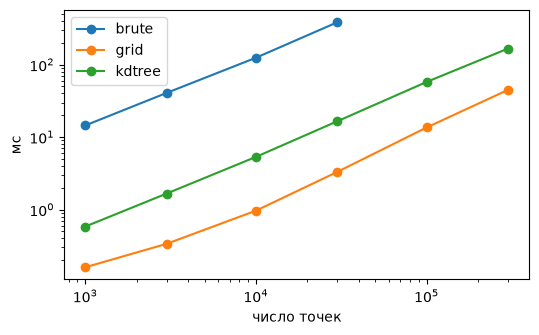

In [7]:
sizes = [1_000, 3_000, 10_000, 30_000, 100_000, 300_000]
res = {m: [] for m in ('brute', 'grid', 'kdtree')}
for M_ in sizes:
    p = random_points(M_)
    for m in res:
        if m == 'brute' and M_ > 30_000:
            res[m].append(np.nan); continue
        res[m].append(timeit(lambda: getattr(det, f'pmt_index_{m}')(p)))
plt.figure(figsize=(6, 3.5))
for m, t in res.items():
    plt.loglog(sizes, np.array(t) * 1e3, 'o-', label=m)
plt.xlabel('число точек'); plt.ylabel('мс'); plt.legend(); plt.show()

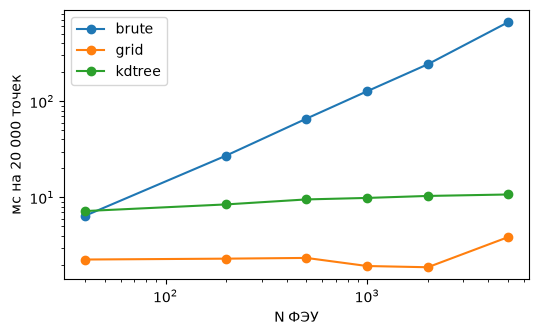

brute    6.45   27.22   65.94  127.05  242.57  663.36
grid    2.26    2.30    2.34    1.93    1.88    3.86
kdtree    7.21    8.45    9.52    9.87   10.35   10.72


In [8]:
Ns = [40, 200, 500, 1000, 2000, 5000]
resN = {m: [] for m in ('brute', 'grid', 'kdtree')}
p0 = rng.normal(size=(20_000, 3)); p0 /= np.linalg.norm(p0, axis=1, keepdims=True)
for N_ in Ns:
    d_ = Detector(R=15.0, N=N_, r=0.10)
    d_.build_grid(); d_.pmt_index_kdtree(p0[:1] * d_.R)   # построение индексов вне замера
    for m in resN:
        resN[m].append(timeit(lambda: getattr(d_, f'pmt_index_{m}')(p0 * d_.R)))
plt.figure(figsize=(6, 3.5))
for m, t in resN.items():
    plt.loglog(Ns, np.array(t) * 1e3, 'o-', label=m)
plt.xlabel('N ФЭУ'); plt.ylabel('мс на 20 000 точек'); plt.legend(); plt.show()
for m, t in resN.items():
    print(m, ' '.join(f'{x*1e3:7.2f}' for x in t))

## Событие 1 МэВ в центре большого детектора

<Q> = 110.83 ± 0.39,  ожидание a*Y*coverage = 111.11


brute  :  123.82 мс / событие
grid   :    1.70 мс / событие
kdtree :    6.08 мс / событие


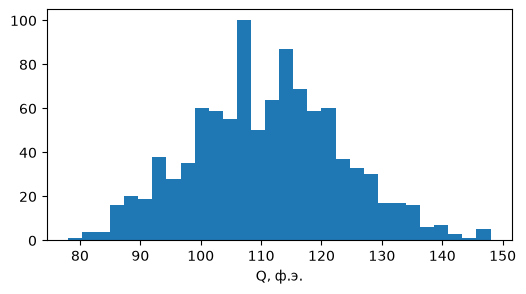

In [9]:
src = Source(Y=10_000, rng=80)
det.search = 'grid'
Qs = np.array([det.response(np.zeros(3), src.directions(1.0)).sum() for _ in range(1000)])
print(f"<Q> = {Qs.mean():.2f} ± {Qs.std()/np.sqrt(len(Qs)):.2f},  ожидание a*Y*coverage = {det.a*src.Y*det.coverage():.2f}")
t = {}
for m in ('brute', 'grid', 'kdtree'):
    det.search = m
    t[m] = timeit(lambda: det.response(np.zeros(3), src.directions(1.0)), 5)
    print(f"{m:7s}: {t[m]*1e3:7.2f} мс / событие")
plt.figure(figsize=(6, 3)); plt.hist(Qs, bins=30); plt.xlabel('Q, ф.э.'); plt.show()

**Выводы.**
- ФЭУ расставлены равномерно: расстояние до ближайшего соседа 1.14 ± 0.015 м (разброс ~1%), покрытие 2.2%. Заряд события 1 МэВ в центре 110.8 ± 0.4 ф.э. при ожидании $aY\cdot$покрытие = 111.1.
- На 20 000 точек при $N = 2000$: перебор 240 мс, k-d дерево 11 мс (×22), сетка **2.0 мс (×122)**. Событие целиком: 124 мс → 6.1 мс (дерево) → **1.7 мс** (сетка).
- Перебор растёт линейно с $N$, k-d дерево — как $\log N$, а время сетки практически не зависит от $N$ (1.9–2.3 мс при $N$ от 40 до 2000 и 3.9 мс при $N = 5000$): ячейка подбирается под расстояние между ФЭУ, и на точку всегда проверяется $K \approx 1$ кандидат.
- Ключевое для скорости сетки — форма ячеек. Первая версия (равный шаг по $\cos\theta$ и $\phi$) давала у полюсов узкие клинья с $K = 37$ и работала за 30 мс. Пояса равной ширины по $\theta$ с числом ячеек $\propto\sin\theta$ дают почти квадратные ячейки и $K = 1$ — ускорение примерно в 15 раз.
- Размер ячейки — компромисс: крупные ячейки дают много кандидатов (при 20 поясах $K = 9$, 9.7 мс), а очень мелкие только увеличивают таблицу: при 80 и 120 поясах время одинаково в пределах разброса замеров (~2 мс).